# Chapitre 7 - Exercices 7.6 à 7.10

* **7.6** : le nombre effectif de paramètres des $k$ plus proches voisins vaut $N/k$ ;
* **7.7** : le lien entre $C_p$/AIC et la validation croisée généralisée ;
* **7.8** : la famille $\{I(\sin(\alpha x) > 0)\}$ a une dimension VC infinie ;
* **7.9** : sélection du meilleur sous-ensemble sur les données de cancer de la prostate
  par AIC, BIC, validation croisée et bootstrap .632 ;
* **7.10** : la validation croisée avec des prédicteurs binaires très nombreux.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch07_selection as sel
set_style()

## Exercice 7.6 : Degrés de liberté des $k$ plus proches voisins

**Énoncé.** Montrer que, pour un modèle à erreur additive, le nombre effectif de
paramètres de l'ajustement par les $k$ plus proches voisins est $N/k$.

**Rappels.** Le nombre effectif de paramètres est défini par (7.33) :
$\mathrm{df}(\hat{\mathbf y}) = \sum_i\mathrm{Cov}(\hat y_i, y_i)/\sigma^2_\varepsilon$, et vaut
$\mathrm{trace}(\mathbf S)$ pour un lisseur linéaire $\hat{\mathbf y} = \mathbf S\mathbf y$
(exercice 7.5). On suppose les $x_i$ fixés et **distincts**, et l'on note $N_k(x_i)$ les
indices des $k$ points d'apprentissage les plus proches de $x_i$.

**Solution.** Aux points d'apprentissage, l'ajustement s'écrit
$\hat y_i = \frac1k\sum_{j\in N_k(x_i)}y_j$ : c'est un lisseur linéaire de matrice
$S_{ij} = \frac1k I(j\in N_k(x_i))$, qui ne dépend que des $x$. Or $x_i$ est à distance
nulle de lui-même : c'est son propre plus proche voisin, donc $i\in N_k(x_i)$ et
$S_{ii} = 1/k$ pour tout $i$. Ainsi

$$\mathrm{df} = \mathrm{trace}(\mathbf S) = \sum_{i=1}^N\frac1k = \frac Nk.$$

Directement avec (7.33) : les $y_j$ étant indépendants,
$\mathrm{Cov}(\hat y_i, y_i) = \frac1k\sum_{j\in N_k(x_i)}\mathrm{Cov}(y_j, y_i) = \frac1k\mathrm{Var}(y_i) = \frac{\sigma^2_\varepsilon}k$,
et la somme sur $i$ divisée par $\sigma^2_\varepsilon$ redonne $N/k$. $\square$

> **Intuition.** Si les $N$ points se répartissaient en $N/k$ groupes disjoints de $k$
> voisins, les $k$-PPV ajusteraient une constante par groupe : $N/k$ paramètres. La formule
> reste vraie même si les voisinages se chevauchent.

**Vérification numérique** : trace de $\mathbf S$ et estimation par simulation de la
covariance, pour $N = 60$ points de $\mathbb R^2$.

In [2]:
rng = np.random.RandomState(0)
N = 60
X = rng.rand(N, 2)
f = np.sin(3 * X[:, 0]) + X[:, 1]
ks = [1, 2, 3, 4, 5, 6, 10, 12, 15, 20, 30, 60]
df_tr, df_mc = [], []
for k in ks:
    S = sel.knn_smoother_matrix(X, k)
    df_tr.append(sel.df_trace(S))
    df_mc.append(sel.df_monte_carlo(lambda y: sel.knn_regression(X, y, X, k), f, 0.7, n_rep=1500, rng=rng))

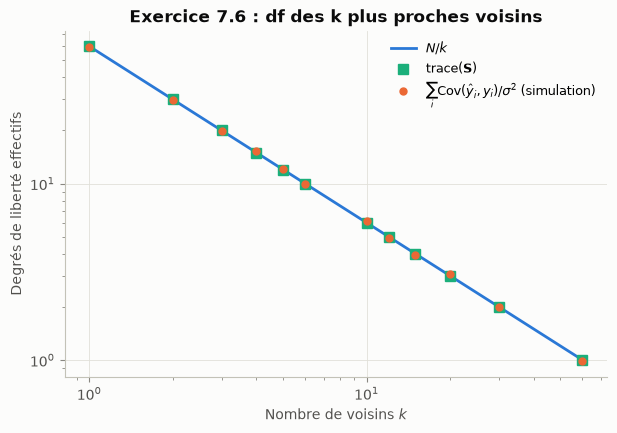

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
kk = np.linspace(1, 60, 300)
ax.plot(kk, N / kk, color=BLUE, label="$N/k$")
ax.plot(ks, df_tr, "s", color=COLORS[2], ms=7, label=r"$\mathrm{trace}(\mathbf{S})$")
ax.plot(ks, df_mc, "o", color=ORANGE, label=r"$\sum_i \mathrm{Cov}(\hat y_i, y_i)/\sigma^2$ (simulation)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Nombre de voisins $k$")
ax.set_ylabel("Degrés de liberté effectifs")
ax.set_title("Exercice 7.6 : df des k plus proches voisins")
ax.legend()
plt.show()

> **À retenir.** Pour les $k$-PPV, $S_{ii} = 1/k$ (chaque point est son propre voisin),
> donc $\mathrm{df} = N/k$ : la complexité est inversement proportionnelle à $k$. C'est la
> valeur utilisée pour AIC/BIC dans les figures 7.7 du livre.

## Exercice 7.7 : Relation entre $C_p$/AIC et GCV

**Énoncé.** À l'aide de l'approximation $1/(1-x)^2\approx 1 + 2x$, mettre en évidence la
relation entre $C_p$/AIC (7.26) et la validation croisée généralisée (7.52), la
principale différence étant le modèle utilisé pour estimer la variance du bruit
$\sigma^2_\varepsilon$.

**Rappels.** Pour un lisseur linéaire de degrés de liberté $\mathrm{df} = \mathrm{trace}(\mathbf S)$,
avec $\overline{\mathrm{err}} = \frac1N\sum_i(y_i - \hat f(x_i))^2$ :

$$C_p = \overline{\mathrm{err}} + 2\,\frac{\mathrm{df}}N\,\hat\sigma^2_\varepsilon,
\qquad
\mathrm{GCV} = \frac{\overline{\mathrm{err}}}{\big(1 - \mathrm{df}/N\big)^2}.$$

**Approximation.** Par développement limité de $u\mapsto(1-u)^{-2}$ en $0$ (dérivée
$2(1-u)^{-3}$, qui vaut $2$ en $0$) : $(1-u)^{-2} = 1 + 2u + O(u^2)$. Avec $u = \mathrm{df}/N$
petit (peu de paramètres devant $N$) :

$$\mathrm{GCV}\approx\overline{\mathrm{err}}\Big(1 + 2\frac{\mathrm{df}}N\Big) = \overline{\mathrm{err}} + 2\,\frac{\mathrm{df}}N\,\overline{\mathrm{err}}.$$